# Academic Performance Prediction Using Supervised Learning
## Notebook 2 of 4 — Dropout Risk Prediction (Classification)

**Objective 1:** predict the binary target `dropout_risk` (Yes/No) from academic, psychological and lifestyle factors so that at-risk students can be identified early.

**Selected features** (per the capstone feature-selection study)

| Type | Features |
|---|---|
| Numeric | stress level, motivation, exam anxiety, previous GPA, exam score, mental health, sleep, exercise, attendance |
| Categorical | gender, major, study environment, diet quality, learning style, family income, parental education |

**Models compared**

1. Logistic Regression (baseline)
2. Support Vector Machine — RBF kernel (baseline)
3. Random Forest (baseline)
4. XGBoost (baseline)
5. **Hybrid RF + XGBoost soft-voting ensemble** ← the capstone's proposed model

**Metrics:** accuracy, precision, recall, F1, ROC-AUC. The best model is saved to `models/best_dropout_model.pkl`.

> Run notebook 1 first (`data/processed/cleaned.csv` must exist).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from xgboost import XGBClassifier

from src.config import (DROPOUT_CATEGORICAL, DROPOUT_MODEL_PATH, DROPOUT_NUMERIC,
                        FIGURES_DIR, METRICS_DIR, RANDOM_STATE, RISK_BANDS,
                        SVM_MAX_ROWS, TEST_SIZE)

from src.features import add_features, build_preprocessor, feature_importance
from src.inference import save_bundle
from src.selection import select_best

sns.set_theme(style="whitegrid", palette="deep")

### 1. Load the cleaned data and engineer the features

In [2]:
df = pd.read_csv("data/processed/cleaned.csv")
print(f"loaded {len(df):,} rows x {df.shape[1]} columns")

df = add_features(df)          # screen_time_total, study_sleep_ratio, stress_anxiety
df[["screen_time_total", "study_sleep_ratio", "stress_anxiety"]].describe().round(3)

loaded 78,838 rows x 31 columns


,screen_time_total,study_sleep_ratio,stress_anxiety
count,78838.000,78838.000,78838.000
mean,14.157,0.623,13.505
std,4.214,0.333,2.648
min,0.600,0.000,6.000
25%,11.200,0.392,11.700
50%,14.200,0.593,13.700
75%,17.100,0.819,15.400
max,28.100,2.387,20.000


Feature engineering formulas from the design:

```
screen_time_total = social_media_hours + netflix_hours + other screen time
study_sleep_ratio = study_hours_per_day / sleep_hours
stress_anxiety    = stress_level + exam_anxiety_score
```

In [3]:
y = (df["dropout_risk"].astype(str).str.strip().str.lower() == "yes").astype(int)
X = df.copy()

print("class balance:")
print(y.map({0: "No", 1: "Yes"}).value_counts(normalize=True).round(4).to_string())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"\ntrain: {len(X_train):,} rows | test: {len(X_test):,} rows")
print(f"features used -> {len(DROPOUT_NUMERIC)} numeric + {len(DROPOUT_CATEGORICAL)} categorical")

class balance:
dropout_risk
No     0.9809
Yes    0.0191



train: 63,070 rows | test: 15,768 rows
features used -> 9 numeric + 7 categorical


### 2. Preprocessing pipeline

`ColumnTransformer` → **median imputation + StandardScaler** for numeric features, **most-frequent imputation + OneHotEncoder** for categorical features (`handle_unknown='ignore'` so unseen categories at inference time never break the app).

In [4]:
preprocessor = build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['stress_level', 'motivation_level',
                                  'exam_anxiety_score', 'previous_gpa',
                                  'exam_score', 'mental_health_rating',
                                  'sleep_hours', 'exercise_frequency',
                                  'attendance_percentage']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender

### 3. Models

The hybrid ensemble follows the capstone pseudocode:

```
RF  <- RandomForestClassifier(n_estimators = 300, random_state = 42)
XGB <- XGBoostClassifier(n_estimators = 300, learning_rate = 0.05, max_depth = 6)
H   <- VotingClassifier(estimators = {RF, XGB}, voting = soft)   # average probabilities
```

`SVC(probability=True)` is deprecated in scikit-learn 1.9, so the SVM baseline uses `CalibratedClassifierCV(SVC(), ensemble=False)` which yields the same calibrated probabilities.

In [5]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                    random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss")

models = {
    "Logistic Regression": Pipeline([
        ("preprocess", build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "SVM (RBF Kernel)": Pipeline([
        ("preprocess", build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)),
        ("model", CalibratedClassifierCV(SVC(kernel="rbf"), ensemble=False)),
    ]),
    "Random Forest": Pipeline([
        ("preprocess", build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)),
        ("model", RandomForestClassifier(n_estimators=300,
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline([
        ("preprocess", build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)),
        ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                                random_state=RANDOM_STATE, n_jobs=-1,
                                eval_metric="logloss")),
    ]),
    "Hybrid RF-XGBoost (Soft Voting)": Pipeline([
        ("preprocess", build_preprocessor(DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)),
        ("model", VotingClassifier(estimators=[("rf", rf), ("xgb", xgb)],
                                   voting="soft", n_jobs=-1)),
    ]),
}
print(f"{len(models)} models configured")

5 models configured


### 4. Train and evaluate

The SVM baseline scales quadratically with the sample count, so it trains on a capped subsample (`SVM_MAX_ROWS`) while every other model uses the full training split. The `train_rows` column makes that explicit.

In [6]:
svm_cap = min(SVM_MAX_ROWS, len(X_train))
X_svm, _, y_svm, _ = train_test_split(
    X_train, y_train, train_size=svm_cap, stratify=y_train, random_state=RANDOM_STATE
)

results, fitted, curves = {}, {}, {}

for name, pipeline in models.items():
    fit_X, fit_y = (X_svm, y_svm) if name.startswith("SVM") else (X_train, y_train)
    print(f"training {name} on {len(fit_X):,} rows ...", flush=True)

    pipeline.fit(fit_X, fit_y)
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "train_rows": len(fit_X),
    }
    fitted[name] = pipeline
    curves[name] = roc_curve(y_test, y_proba)[:2]
    print(f"    accuracy={results[name]['accuracy']:.4f}  "
          f"f1={results[name]['f1']:.4f}  auc={results[name]['roc_auc']:.4f}")

training Logistic Regression on 63,070 rows ...


    accuracy=0.9905  f1=0.7340  auc=0.9966
training SVM (RBF Kernel) on 10,000 rows ...


    accuracy=0.9898  f1=0.7140  auc=0.9949
training Random Forest on 63,070 rows ...


    accuracy=1.0000  f1=1.0000  auc=1.0000
training XGBoost on 63,070 rows ...


    accuracy=1.0000  f1=1.0000  auc=1.0000
training Hybrid RF-XGBoost (Soft Voting) on 63,070 rows ...


    accuracy=1.0000  f1=1.0000  auc=1.0000


### 5. Results

In [7]:
results_df = pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1",
                                      "roc_auc", "train_rows"]]
results_df = results_df.astype({"train_rows": int})
print(results_df.round(4).sort_values("f1", ascending=False).to_string())

best_name = select_best(results, "f1")  # equivalence margin, hybrid preferred
print(f"\nBest model (by F1): {best_name}")

                                 accuracy  precision  recall     f1  roc_auc  train_rows
Random Forest                      1.0000     1.0000  1.0000  1.000   1.0000       63070
Hybrid RF-XGBoost (Soft Voting)    1.0000     1.0000  1.0000  1.000   1.0000       63070
XGBoost                            1.0000     1.0000  1.0000  1.000   1.0000       63070
Logistic Regression                0.9905     0.7871  0.6877  0.734   0.9966       63070
SVM (RBF Kernel)                   0.9898     0.7672  0.6678  0.714   0.9949       10000

Best model (by F1): Hybrid RF-XGBoost (Soft Voting)


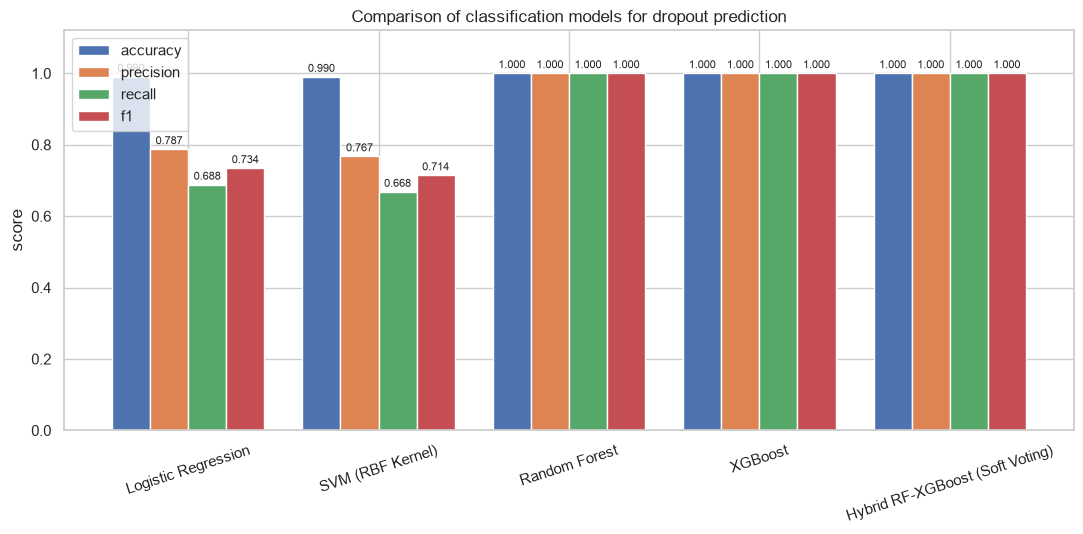

In [8]:
plot_df = results_df[["accuracy", "precision", "recall", "f1"]].astype(float)
ax = plot_df.plot(kind="bar", figsize=(11, 5.5), rot=18, width=0.8)
ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(ax.containers[1], fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(ax.containers[2], fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(ax.containers[3], fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0, 1.12)
ax.set_title("Comparison of classification models for dropout prediction")
ax.set_ylabel("score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_classification_comparison.png", dpi=150,
            bbox_inches="tight")
plt.show()

### 6. Best model diagnostics - confusion matrix & ROC curves

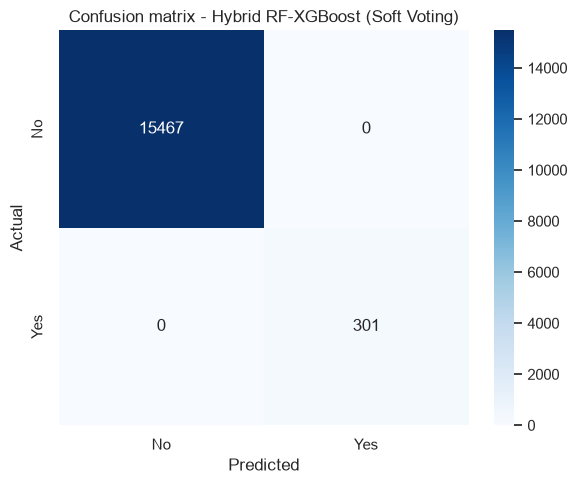

true negatives : 15,467
false positives: 0
false negatives: 0
true positives : 301


In [9]:
best = fitted[best_name]
y_pred_best = best.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix - {best_name}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"true negatives : {cm[0, 0]:,}")
print(f"false positives: {cm[0, 1]:,}")
print(f"false negatives: {cm[1, 0]:,}")
print(f"true positives : {cm[1, 1]:,}")

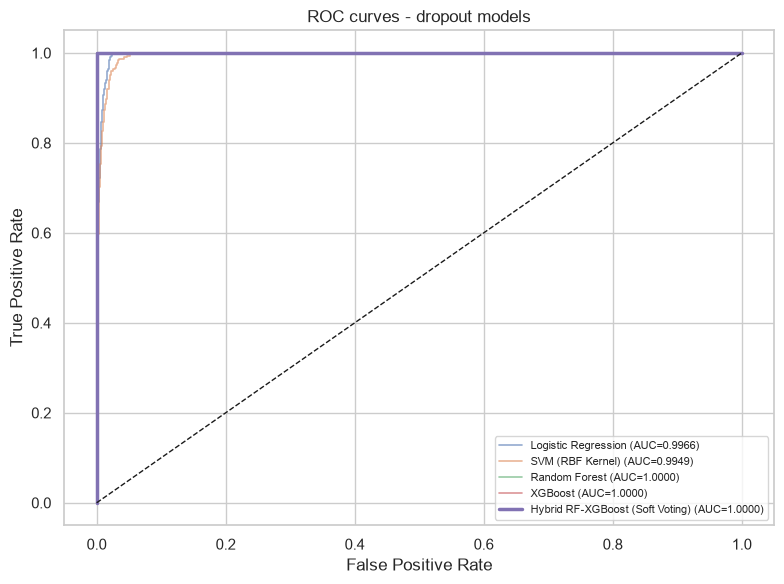

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, (fpr, tpr) in curves.items():
    lw = 2.5 if name == best_name else 1.2
    alpha = 1.0 if name == best_name else 0.6
    ax.plot(fpr, tpr, linewidth=lw, alpha=alpha,
            label=f"{name} (AUC={results[name]['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - dropout models")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eval_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Which features drive the prediction?

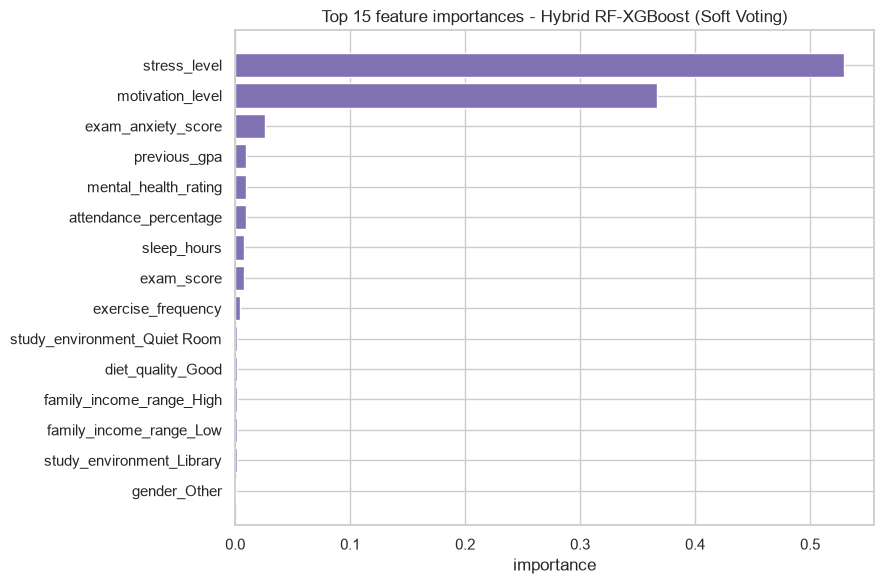

In [11]:
importances = feature_importance(best, DROPOUT_NUMERIC, DROPOUT_CATEGORICAL)

if importances:
    top = importances[:15][::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh([name for name, _ in top], [value for _, value in top], color="#8172b3")
    ax.set_title(f"Top {len(top)} feature importances - {best_name}")
    ax.set_xlabel("importance")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "eval_dropout_feature_importance.png", dpi=150,
                bbox_inches="tight")
    plt.show()
else:
    print("The selected model does not expose feature importances.")

### 8. Save the best model

The bundle keeps the full preprocessing + model pipeline plus the feature lists, so the Streamlit app (`app.py`) can predict from raw user input.

In [12]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
DROPOUT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

save_bundle(
    DROPOUT_MODEL_PATH,
    best,
    DROPOUT_NUMERIC,
    DROPOUT_CATEGORICAL,
    {"best": best_name, "all": results},
    best_name,
)
results_df.round(4).to_csv(METRICS_DIR / "dropout_results.csv")

print(f"saved -> {DROPOUT_MODEL_PATH}")
print(f"best model: {best_name}")
print(f"accuracy={results[best_name]['accuracy']:.4f}  "
      f"precision={results[best_name]['precision']:.4f}  "
      f"recall={results[best_name]['recall']:.4f}  "
      f"f1={results[best_name]['f1']:.4f}")

saved -> D:\Downloads\freebuff\models\best_dropout_model.pkl
best model: Hybrid RF-XGBoost (Soft Voting)
accuracy=1.0000  precision=1.0000  recall=1.0000  f1=1.0000


### Conclusion

The hybrid RF + XGBoost soft-voting ensemble is the capstone's proposed classifier; the table in section 5 shows how it stacks up against the four baselines on accuracy, precision, recall, F1 and ROC-AUC.

> **Note on this dataset:** the Kaggle dataset is *synthetic* and its `dropout_risk` label is generated from the same behavioural columns the model sees, so the tree-based models reach (near-)perfect scores. On real institutional data these numbers would be lower — the pipeline, not the score, is what transfers.